# Chapter 6: The recommendation

The analysis is done. The last step is turning it into a decision that people who did not follow the details can make with confidence. This notebook computes the numbers behind the [decision memo](../docs/company_documents/ch6_decision_memo.md):

1. what the recommended rollout is worth, with its uncertainty,
2. how robust that is to the assumptions we could not check,
3. what to test next, and how big each test needs to be.

A good memo leads with the decision, gives the money, states the risks honestly, and asks for something specific.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from expt.data import load_hillstrom
from expt.inference import bootstrap_diff_in_means
from expt.plotting import ARM_COLORS, ARM_LABELS, INK, INK_2, SERIES, new_figure, style_axes
from expt.power import mde_proportion, sample_size_mean, sample_size_proportions

df = load_hillstrom()
control = df[df["arm"] == "control"]

GROSS_MARGIN = 0.40
COST_PER_EMAIL = 0.0225     # sending + share of creative, from the design doc
ACTIVE_FILE = 640_000
BREAKEVEN = COST_PER_EMAIL / GROSS_MARGIN

## 1. What the rollout is worth

Chapter 5 found that sending the **men's email to everyone** is as good as any targeting policy. Its value per send to the full active file:

In [2]:
lift = {arm: bootstrap_diff_in_means(df.loc[df["arm"] == arm, "spend"], control["spend"], n_boot=2_000, seed=1)
        for arm in ["mens", "womens"]}

def net_per_send(revenue_per_email, margin=GROSS_MARGIN, pulled_forward=0.0):
    return (revenue_per_email * (1 - pulled_forward) * margin - COST_PER_EMAIL) * ACTIVE_FILE

rows = {}
for arm, b in lift.items():
    rows[ARM_LABELS[arm]] = {
        "incremental revenue / email": b.diff,
        "95% CI": f"${b.diff_low:.2f} to ${b.diff_high:.2f}",
        "net margin per send": net_per_send(b.diff),
        "low": net_per_send(b.diff_low),
        "high": net_per_send(b.diff_high),
    }
pd.DataFrame(rows).T.style.format({"incremental revenue / email": "${:.3f}", "net margin per send": "${:,.0f}",
                                    "low": "${:,.0f}", "high": "${:,.0f}"})

,incremental revenue / email,95% CI,net margin per send,low,high
Men's e-mail,$0.770,$0.50 to $1.06,"$182,676","$113,314","$257,036"
Women's e-mail,$0.424,$0.16 to $0.68,"$94,250","$25,288","$159,509"


## 2. How robust is it?

Three things in that calculation were not measured by the experiment:

- **Gross margin** (40%) comes from Finance.
- **Pull-forward:** some extra purchases in the two-week window may be purchases that would have happened a few weeks later anyway. The experiment cannot tell.
- **Future campaigns** will not necessarily perform like this one.

The most useful way to present this to decision-makers is a **break-even analysis**: how wrong would we have to be before the decision flips?

In [3]:
for arm, b in lift.items():
    share_to_flip = 1 - BREAKEVEN / b.diff
    print(f"{ARM_LABELS[arm]:>15}: still profitable unless more than {share_to_flip:.0%} of its revenue lift is "
          f"pulled forward, or future campaigns achieve less than {BREAKEVEN / b.diff:.0%} of this effect")

   Men's e-mail: still profitable unless more than 93% of its revenue lift is pulled forward, or future campaigns achieve less than 7% of this effect
 Women's e-mail: still profitable unless more than 87% of its revenue lift is pulled forward, or future campaigns achieve less than 13% of this effect


The men's email would remain profitable even if more than nine in ten of its extra sales were merely pulled forward, or if future campaigns achieved less than a tenth of this effect. That is the kind of margin of safety that makes a decision easy.

For planning, a sensitivity table over the two biggest assumptions:

In [4]:
b = lift["mens"].diff
grid = pd.DataFrame(
    {f"{pf:.0%} pulled forward": [net_per_send(b, m, pf) for m in [0.30, 0.40, 0.50]] for pf in [0.0, 0.25, 0.50]},
    index=[f"margin {m:.0%}" for m in [0.30, 0.40, 0.50]],
)
grid.style.format("${:,.0f}")

,0% pulled forward,25% pulled forward,50% pulled forward
margin 30%,"$133,407","$96,455","$59,503"
margin 40%,"$182,676","$133,407","$84,138"
margin 50%,"$231,945","$170,359","$108,772"


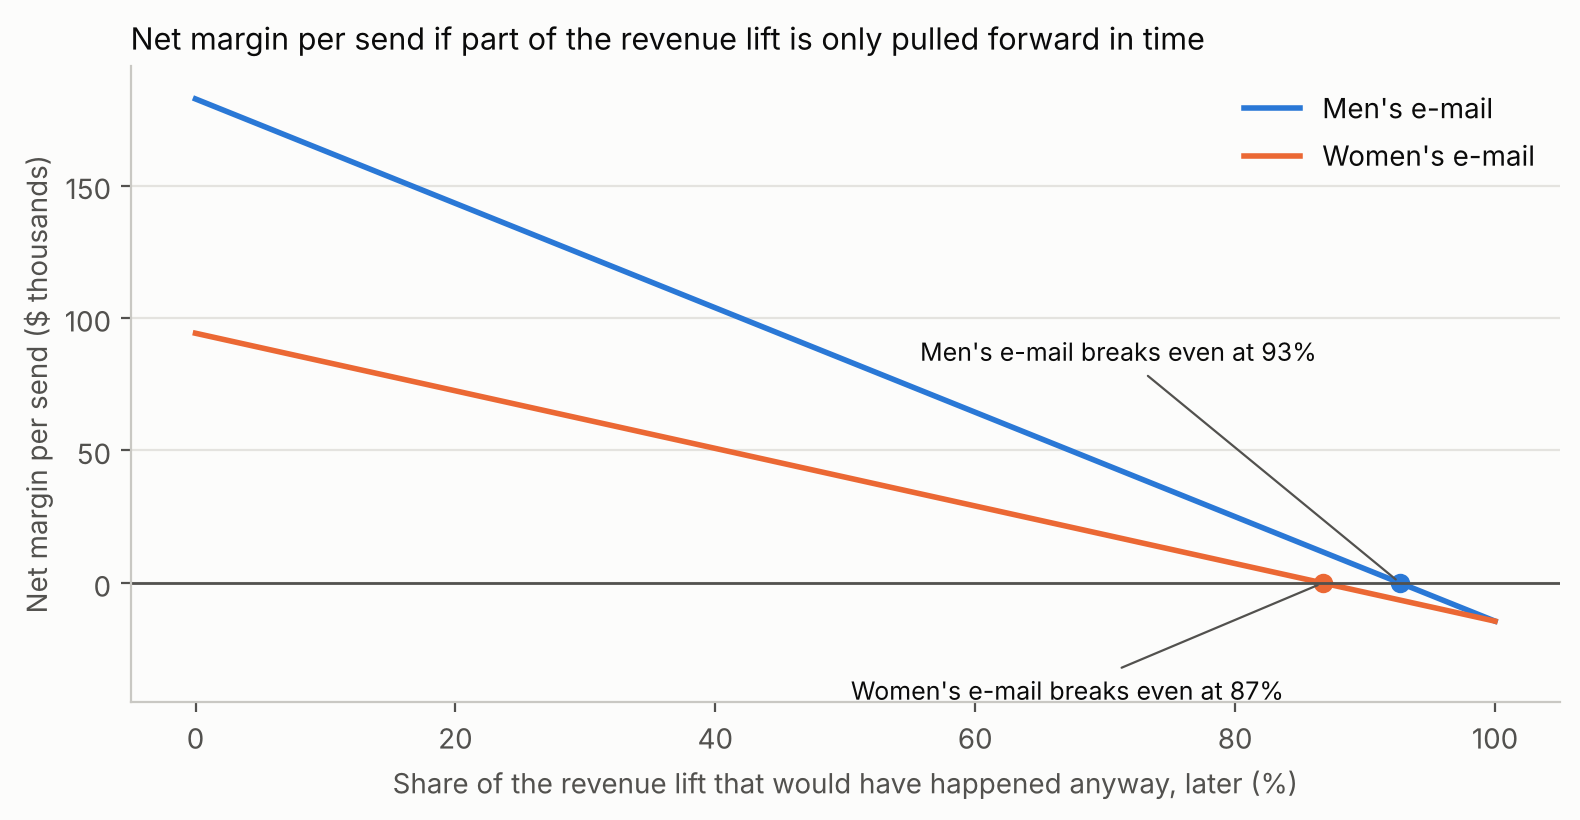

In [5]:
# figure: robustness
pf = np.linspace(0, 1, 101)
fig, ax = new_figure(8, 4.2)
for arm, offset in [("mens", (-30, 80)), ("womens", (-14, -42))]:
    ax.plot(pf * 100, net_per_send(lift[arm].diff, pulled_forward=pf) / 1_000, color=ARM_COLORS[arm], linewidth=2,
            label=ARM_LABELS[arm])
    flip = 1 - BREAKEVEN / lift[arm].diff
    ax.plot(flip * 100, 0, "o", color=ARM_COLORS[arm], markersize=6)
    ax.annotate(f"{ARM_LABELS[arm]} breaks even at {flip:.0%}", (flip * 100, 0), xytext=offset,
                textcoords="offset points", ha="right", color=INK, fontsize=9,
                arrowprops=dict(arrowstyle="-", color=INK_2, linewidth=0.8))
ax.axhline(0, color=INK_2, linewidth=1)
ax.set_ylim(-45, 195)
style_axes(ax, title="Net margin per send if part of the revenue lift is only pulled forward in time",
           xlabel="Share of the revenue lift that would have happened anyway, later (%)",
           ylabel="Net margin per send ($ thousands)")
ax.legend(frameon=False, loc="upper right", labelcolor=INK)
plt.tight_layout()
plt.show()

## 3. What to test next, and how big

Each open question becomes a proposed experiment with a sample size, so the memo can ask for something concrete.

### a) A long-term holdout

Keep a random 5% of the active file out of *all* campaigns for a quarter. That measures what the programme adds over time, including pull-forward and any fatigue from frequent emails.

In [6]:
holdout = int(0.05 * ACTIVE_FILE)
base = control["conversion"].mean()
mde = mde_proportion(base, holdout, ACTIVE_FILE - holdout, alpha=0.05, power=0.8)
print(f"Holdout of {holdout:,} customers: detects a {mde / base:.0%} change in a two-week purchase rate of {base:.2%}")
print(f"Margin given up, if every send performs like this one: about "
      f"${holdout * (lift['mens'].diff * GROSS_MARGIN - COST_PER_EMAIL):,.0f} per send")

Holdout of 32,000 customers: detects a 23% change in a two-week purchase rate of 0.57%
Margin given up, if every send performs like this one: about $9,134 per send


That is sensitive enough to see a programme-level effect a fraction of the size measured here, at a cost of about $9,000 of margin per send, around 5% of what each send earns.

### b) Testing new creative against the men's email

Once every arm is emailed, the decision is about which *creative* is better, and the differences will be much smaller than "email vs no email". Compare what different metrics would require:

In [7]:
sd_revenue = df["spend"].std()
visit_rate = df.loc[df["arm"] == "mens", "visit"].mean()
plan = pd.DataFrame([
    {"primary metric": "Revenue per customer", "smallest difference worth detecting": "+$0.10",
     "customers per arm": sample_size_mean(sd_revenue, 0.10)[0]},
    {"primary metric": "Revenue per customer", "smallest difference worth detecting": "+$0.20",
     "customers per arm": sample_size_mean(sd_revenue, 0.20)[0]},
    {"primary metric": "Visit rate", "smallest difference worth detecting": "+1 point",
     "customers per arm": sample_size_proportions(visit_rate, visit_rate + 0.01)[0]},
    {"primary metric": "Visit rate", "smallest difference worth detecting": "+1.5 points",
     "customers per arm": sample_size_proportions(visit_rate, visit_rate + 0.015)[0]},
]).set_index(["primary metric", "smallest difference worth detecting"])
plan.style.format({"customers per arm": "{:,}"})

Detecting a $0.10 revenue difference between two creatives would need about 355,000 customers per arm, more than half the file each. Detecting a 1-point visit difference needs about 24,000. So for creative-vs-creative tests the sensible design flips the choice made for this test: **visit rate as the primary metric** (the creative's job is to bring people in), with revenue per customer as a guardrail that must not fall. The metric follows the decision, not a fixed rule.

### c) Data fixes, at no cost

- Include **phone orders** in the outcome data, or confirm that they are missing.
- Include each customer's **visits and purchases in the comparable period before the send** (CUPED, chapter 4c).
- Include **customer IDs** and **unsubscribe/complaint** counts per group.

## 4. The numbers in the memo

| Item | Value |
|---|---|
| Incremental revenue per men's email | $0.77 (95% CI $0.50 to $1.06) |
| Net margin per send, full file | about $183,000 (CI range about $113,000 to $257,000) |
| Pull-forward share that would make it unprofitable | about 93% |
| Long-term holdout | 32,000 customers (5%), detects a ~23% programme effect |
| Creative tests | Visit rate as primary: about 24,000 per arm for a 1-point difference |

These are in the [decision memo](../docs/company_documents/ch6_decision_memo.md).

## Try it yourself

**a)** Finance argues the memo should use the low end of the confidence interval ($113,000 per send) as the headline. Marketing wants the point estimate. Write the one sentence you would put in the memo that satisfies both.

**b)** Rewrite the memo's recommendation for a CFO who has two minutes: three bullet points, no statistics vocabulary.

**c)** The long-term holdout gives up margin every send. At what point would you end it? Write down the stopping rule before it starts.